f(x) = x + 1

x2 x1 x0

- x0 always flips (1 becomes 0, 0 becomes 1)
- The second bit flips only when the first bit is 1.
- The third bit flips only when the first two bits are 1.
- The fourth bit flips only when all three input bits are 1.

In [36]:
from qiskit import QuantumCircuit, transpile, ClassicalRegister, QuantumRegister
from qiskit_aer import AerSimulator

In [37]:
def incrementer():
    # q0,q1,q2 = input
    # q3,q4,q5,q6 = output

    input_register = QuantumRegister(3, name='input')
    output_register = QuantumRegister(4, name='output')
    output_classical_register = ClassicalRegister(4, name='output_classical')
    qc = QuantumCircuit(input_register, output_register, output_classical_register)
    qc.barrier()

    # Output bit 0 = NOT x0
    qc.x(3)
    qc.cx(0, 3)
    qc.barrier()

    # Output bit 1 = x1 XOR x0
    qc.cx(1, 4)
    qc.cx(0, 4)
    qc.barrier()

    # Output bit 2 = x2 XOR (x1 AND x0)
    qc.cx(2, 5)
    qc.ccx(1, 0, 5)
    qc.barrier()

    # Output bit 3 = x2 AND x1 AND x0
    qc.mcx([0, 1, 2], 6)
    qc.barrier()

    return qc

In [38]:
simulator = AerSimulator()
oracle = incrementer()

Input = 000 (0), Output = 0001 (1)


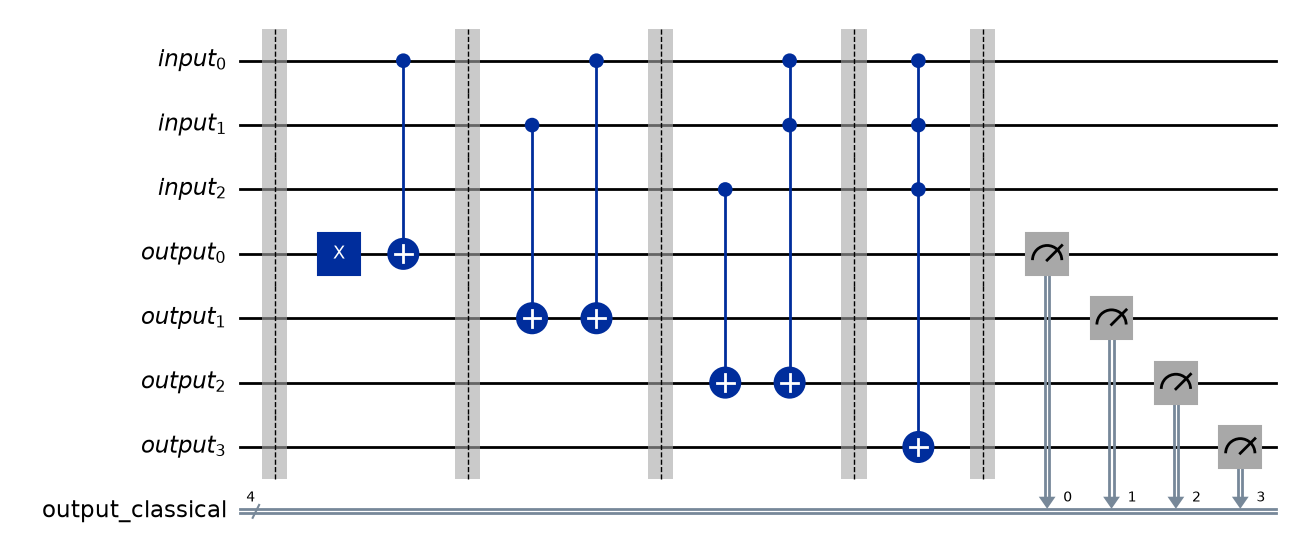

Input = 001 (1), Output = 0010 (2)


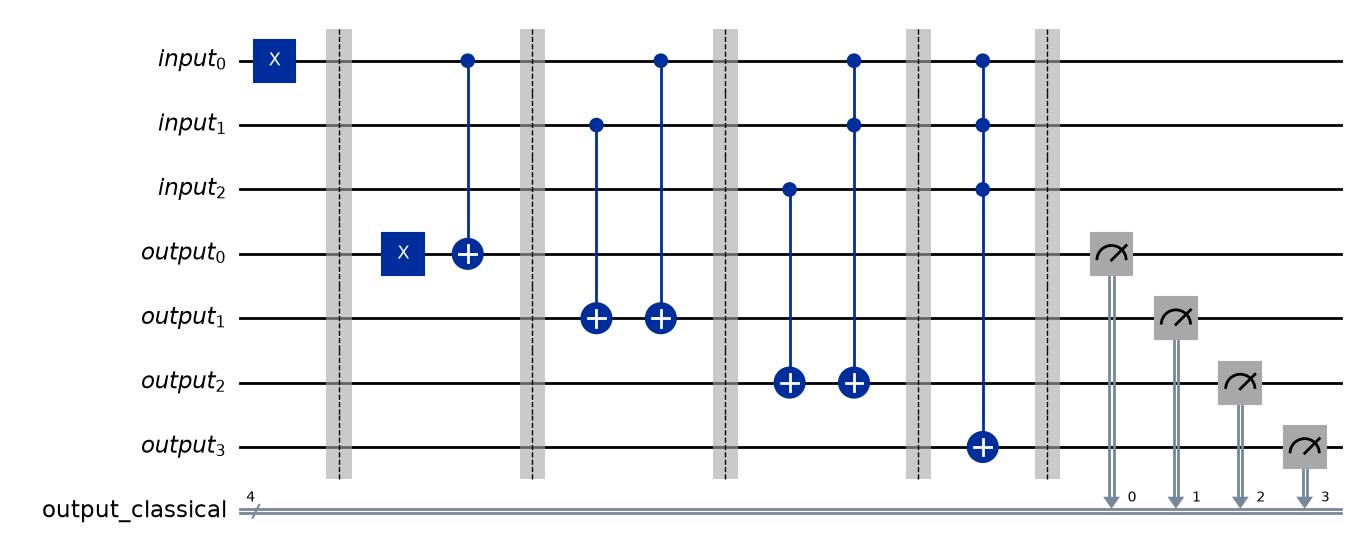

Input = 010 (2), Output = 0011 (3)


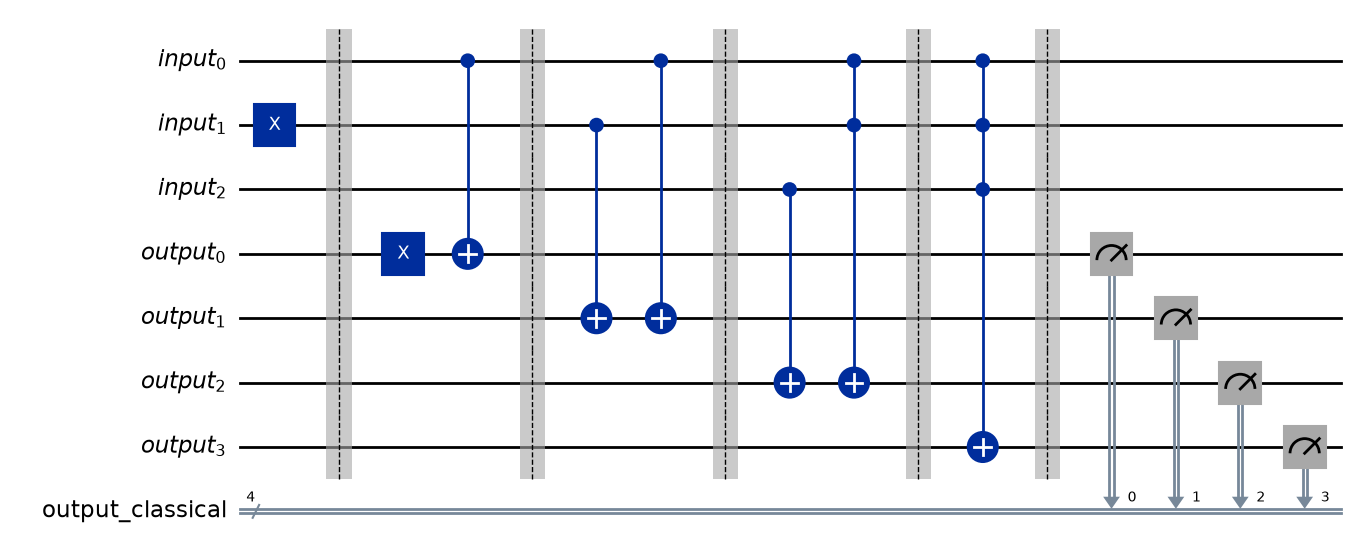

Input = 011 (3), Output = 0100 (4)


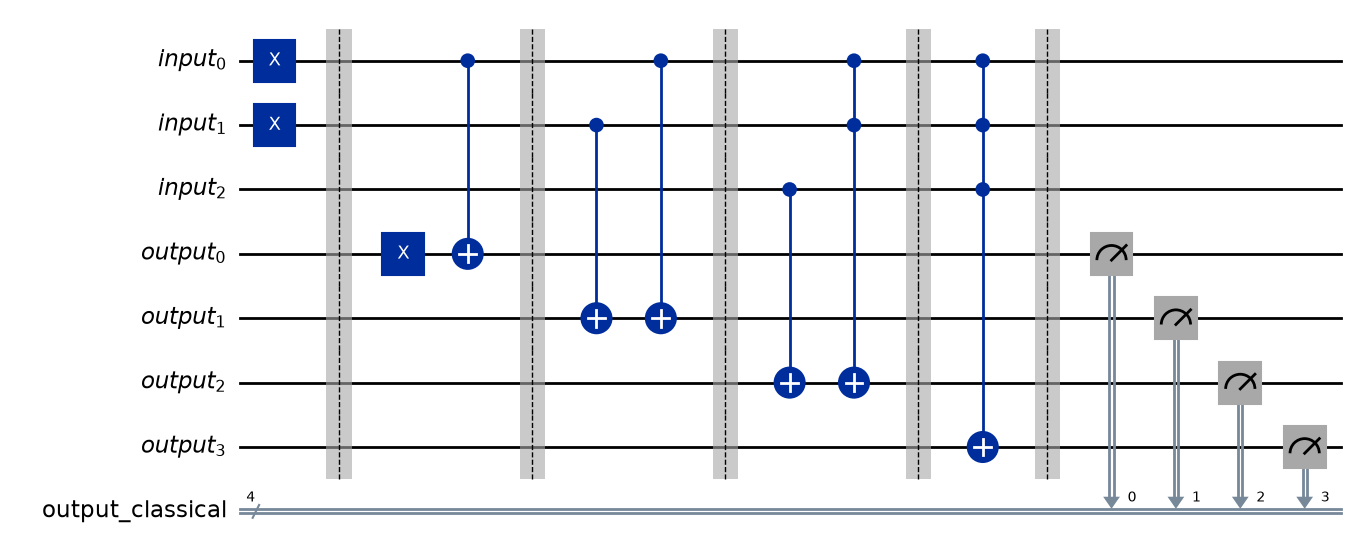

Input = 100 (4), Output = 0101 (5)


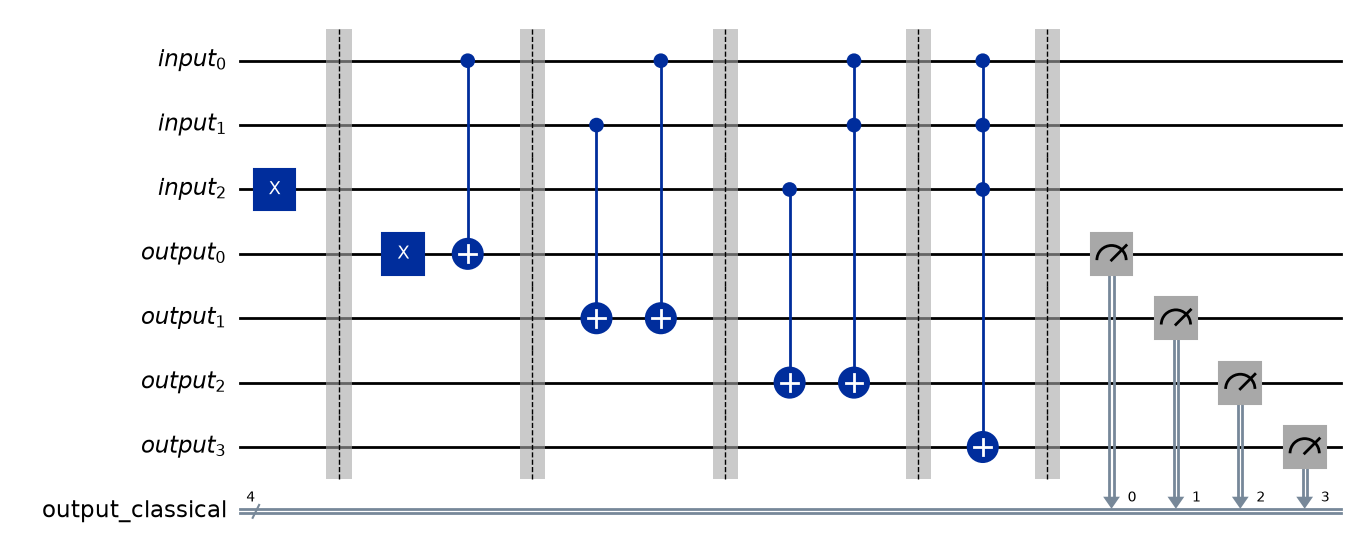

Input = 101 (5), Output = 0110 (6)


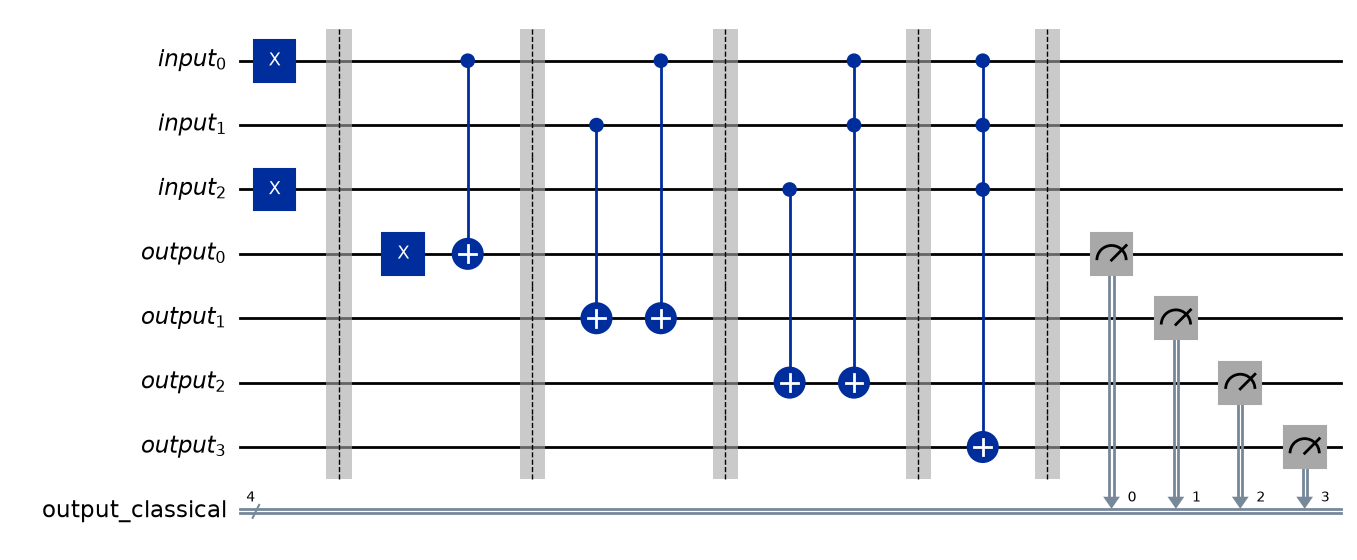

Input = 110 (6), Output = 0111 (7)


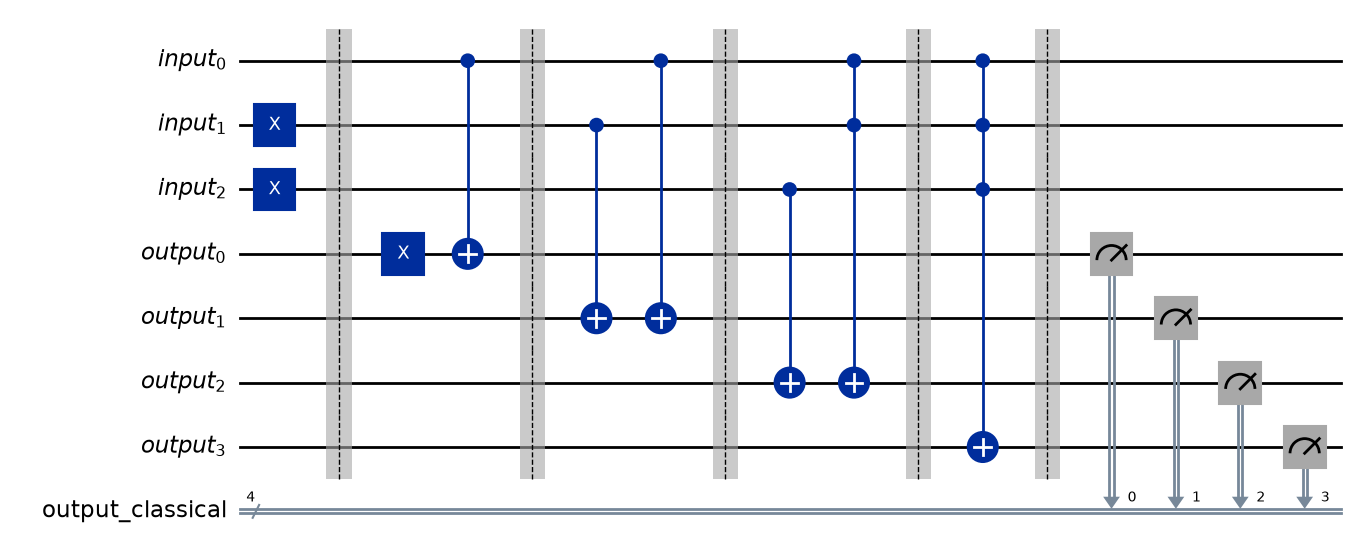

Input = 111 (7), Output = 1000 (8)


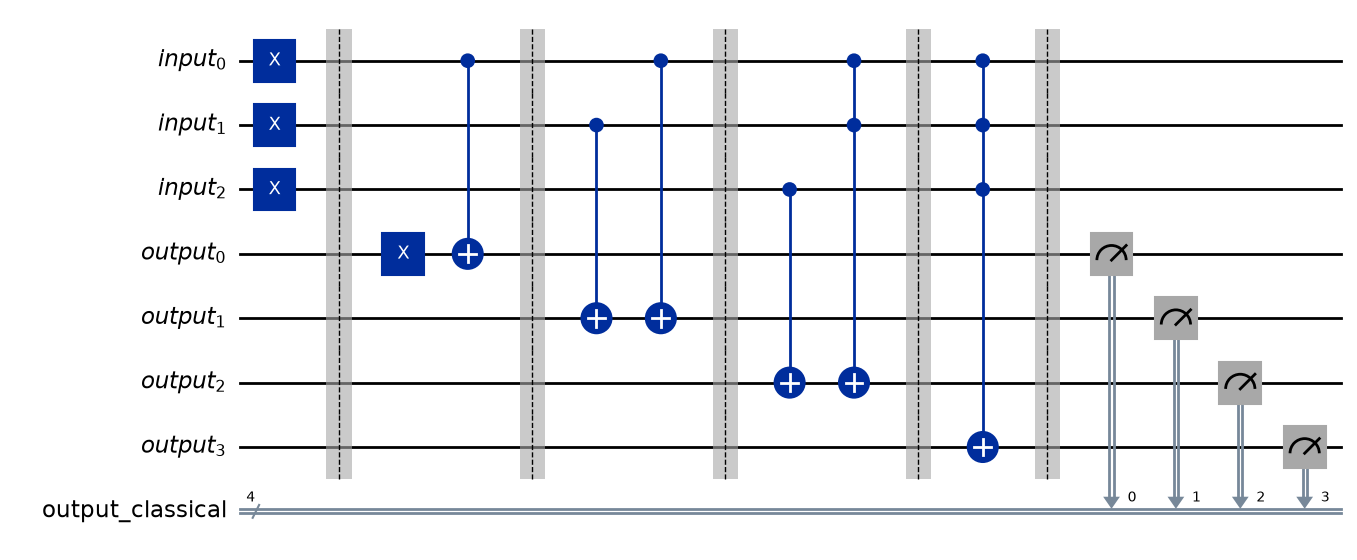

In [39]:
for x in range(8):
    input_register = QuantumRegister(3, name='input')
    output_register = QuantumRegister(4, name='output')
    output_classical_register = ClassicalRegister(4, name='output_classical')
    qc = QuantumCircuit(input_register, output_register, output_classical_register)

    # encode classical input x into quantum register
    for i in range(3):
        if (x >> i) & 1:
            qc.x(i)

    qc.compose(oracle, inplace=True)
    qc.measure([3, 4, 5, 6], [0, 1, 2, 3])
    result = simulator.run(transpile(qc, simulator), shots=1).result()
    bits = next(iter(result.get_counts()))
    output = int(bits, 2)

    print(f"Input = {x:03b} ({x}), Output = {bits} ({output})")
    display(qc.draw(output='mpl'))